# CF4 Density vs NPE Plot

Plots digitized data and MC points from `cf4_data.csv` (fallback: `cf4_gasData.csv`).

- Columns 1-2: data (`x`, `y`)
- Columns 3-4: MC (`x`, `y`)
- Column 5: ignored
- Column 6: MC error-bar top in `y` (converted to `yerr = |col6 - col4|`)

Uses Knicks colors (`#1f51ba` blue, `#F58426` orange).

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 11,
})

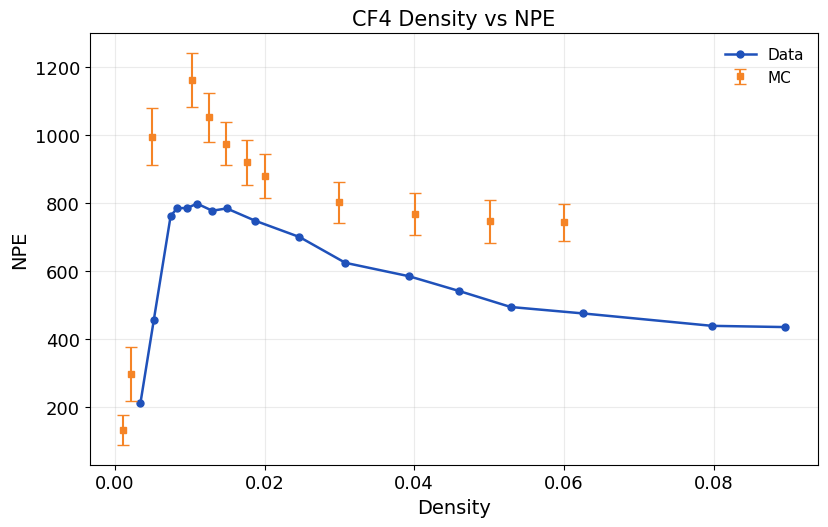

In [38]:
# New York Knicks colors
knicks_blue = "#1f51ba"
knicks_orange = "#F58426"

csv_path = Path("cf4_data.csv")
if not csv_path.exists():
    csv_path = Path("cf4_gasData.csv")

# Keep initial spaces in headers from WebPlotDigitizer exports
df = pd.read_csv(csv_path, skipinitialspace=True)
df.columns = [c.strip() for c in df.columns]

data_x = df["data x"]
data_y = df["datay"]

mc_x = df["MC x"]
mc_y = df["MC Y"]
mc_err_y_top = df["mcError y"]

mc = pd.DataFrame({"x": mc_x, "y": mc_y, "y_top": mc_err_y_top}).dropna()
mc_yerr = (mc["y_top"] - mc["y"]).abs()

fig, ax = plt.subplots(figsize=(8.5, 5.5))

ax.plot(
    data_x,
    data_y,
    marker="o",
    markersize=5,
    linestyle="-",
    linewidth=1.8,
    color=knicks_blue,
    label="Data",
)

ax.errorbar(
    mc["x"],
    mc["y"],
    yerr=mc_yerr,
    fmt="s",
    markersize=5,
    capsize=4,
    elinewidth=1.5,
    linewidth=1.5,
    color=knicks_orange,
    ecolor=knicks_orange,
    label="MC",
)

ax.set_xlabel("Density")
ax.set_ylabel("NPE")
ax.set_title("CF4 Density vs NPE")
ax.grid(alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## CF4 m70C Properties: Density vs Pressure

Load `cf4_m70C_properties.txt` as a tab-delimited table and plot density as a function of pressure.

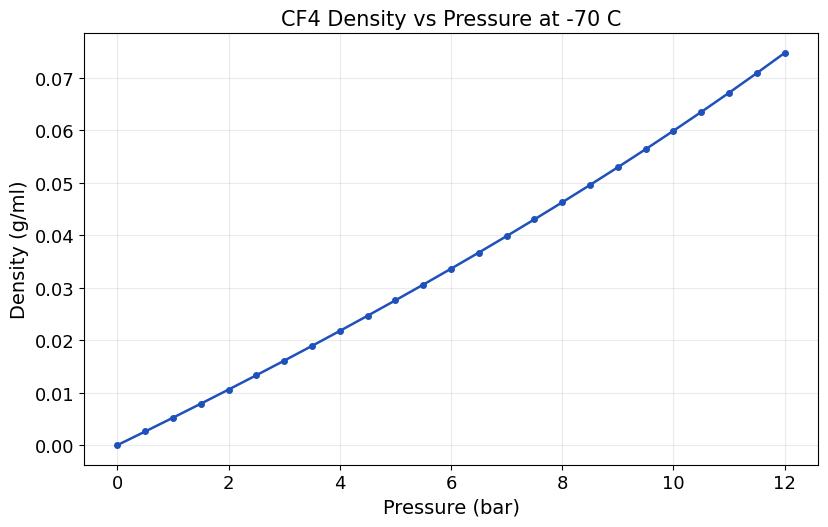

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

# Knicks blue for consistency with your earlier style
knicks_blue = "#1f51ba"

props = pd.read_csv("cf4_m70C_properties.txt", sep="\t")
props.columns = [c.strip() for c in props.columns]

pressure = pd.to_numeric(props["Pressure (bar)"], errors="coerce")
density = pd.to_numeric(props["Density (g/ml)"], errors="coerce")

mask = pressure.notna() & density.notna()
pressure = pressure[mask]
density = density[mask]

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(
    pressure,
    density,
    color=knicks_blue,
    marker="o",
    markersize=4,
    linewidth=1.8,
)

ax.set_xlabel("Pressure (bar)")
ax.set_ylabel("Density (g/ml)")
ax.set_title("CF4 Density vs Pressure at -70 C")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


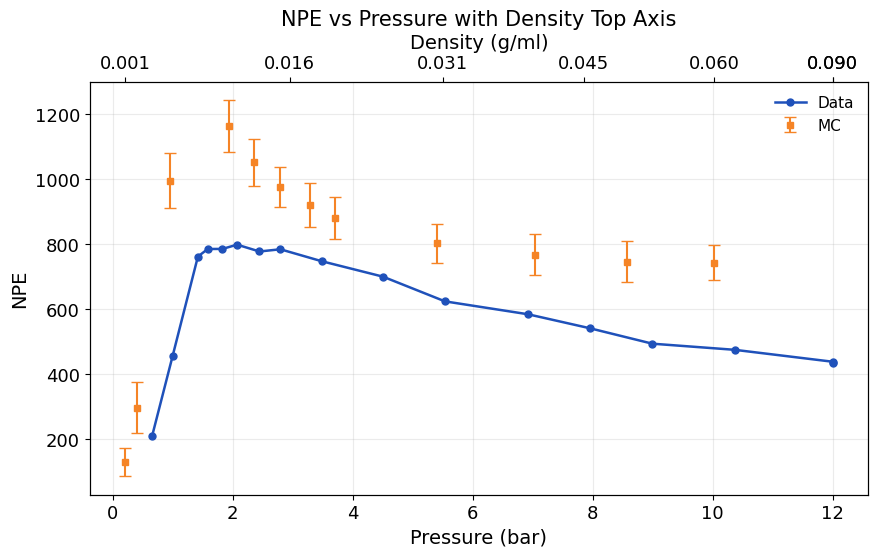

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Knicks colors
knicks_blue = "#1f51ba"
knicks_orange = "#F58426"

# ---------------------------
# 1) Build rho(P) and P(rho)
# ---------------------------
props = pd.read_csv("cf4_m70C_properties.txt", sep="\t", skipinitialspace=True)
props.columns = [c.strip() for c in props.columns]

p_raw = pd.to_numeric(props["Pressure (bar)"], errors="coerce").to_numpy()
rho_raw = pd.to_numeric(props["Density (g/ml)"], errors="coerce").to_numpy()
valid = np.isfinite(p_raw) & np.isfinite(rho_raw)

p_raw = p_raw[valid]
rho_raw = rho_raw[valid]

# rho(P): sort by pressure
order_p = np.argsort(p_raw)
p_sorted = p_raw[order_p]
rho_from_p_sorted = rho_raw[order_p]
p_unique, p_unique_idx = np.unique(p_sorted, return_index=True)
rho_unique_from_p = rho_from_p_sorted[p_unique_idx]

# P(rho): sort by density
order_rho = np.argsort(rho_raw)
rho_sorted = rho_raw[order_rho]
p_from_rho_sorted = p_raw[order_rho]
rho_unique, rho_unique_idx = np.unique(rho_sorted, return_index=True)
p_unique_from_rho = p_from_rho_sorted[rho_unique_idx]


def rho_of_p(p_bar):
    p_bar = np.asarray(p_bar, dtype=float)
    return np.interp(p_bar, p_unique, rho_unique_from_p)


def p_of_rho(rho):
    rho = np.asarray(rho, dtype=float)
    return np.interp(rho, rho_unique, p_unique_from_rho)

# ----------------------------------------------------
# 2) Load digitized data and map density -> pressure
# ----------------------------------------------------
csv_path = Path("cf4_data.csv")
if not csv_path.exists():
    csv_path = Path("cf4_gasData.csv")

df = pd.read_csv(csv_path, skipinitialspace=True)
df.columns = [c.strip() for c in df.columns]

data_rho = pd.to_numeric(df["data x"], errors="coerce")
data_y = pd.to_numeric(df["datay"], errors="coerce")

mc_rho = pd.to_numeric(df["MC x"], errors="coerce")
mc_y = pd.to_numeric(df["MC Y"], errors="coerce")
mc_err_y_top = pd.to_numeric(df["mcError y"], errors="coerce")

data = pd.DataFrame({"rho": data_rho, "y": data_y}).dropna()
mc = pd.DataFrame({"rho": mc_rho, "y": mc_y, "y_top": mc_err_y_top}).dropna()
mc_yerr = (mc["y_top"] - mc["y"]).abs()

data_p = p_of_rho(data["rho"].to_numpy())
mc_p = p_of_rho(mc["rho"].to_numpy())

# ----------------------------------------------------
# 3) Replot NPE with dual x-axes
#    bottom: Pressure (bar)
#    top:    Density (g/ml)
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5.8))

ax.plot(
    data_p,
    data["y"],
    marker="o",
    markersize=5,
    linestyle="-",
    linewidth=1.8,
    color=knicks_blue,
    label="Data",
)

ax.errorbar(
    mc_p,
    mc["y"],
    yerr=mc_yerr,
    fmt="s",
    markersize=5,
    capsize=4,
    elinewidth=1.5,
    linewidth=1.5,
    color=knicks_orange,
    ecolor=knicks_orange,
    label="MC",
)

ax.set_xlabel("Pressure (bar)")
ax.set_ylabel("NPE")
ax.set_title("NPE vs Pressure with Density Top Axis")
ax.grid(alpha=0.25)
ax.legend(frameon=False)

# Top axis shows density tick labels at mapped pressure positions
ax_top = ax.twiny()
ax_top.set_xlim(ax.get_xlim())

rho_min = np.nanmin(np.concatenate([data["rho"].to_numpy(), mc["rho"].to_numpy()]))
rho_max = np.nanmax(np.concatenate([data["rho"].to_numpy(), mc["rho"].to_numpy()]))
rho_ticks = np.linspace(rho_min, rho_max, 7)
p_tick_positions = p_of_rho(rho_ticks)

ax_top.set_xticks(p_tick_positions)
ax_top.set_xticklabels([f"{r:.3f}" for r in rho_ticks])
ax_top.set_xlabel("Density (g/ml)")

fig.tight_layout()
plt.show()


In [41]:
# Math cell: build interpolation + transformed arrays + ratio inputs
import numpy as np
import pandas as pd
from pathlib import Path

# Knicks colors (reused by plotting cell)
knicks_blue = "#1f51ba"
knicks_orange = "#F58426"

# 1) Build rho(P) and P(rho) mappings from CF4 properties
props_math = pd.read_csv("cf4_m70C_properties.txt", sep="\t", skipinitialspace=True)
props_math.columns = [c.strip() for c in props_math.columns]

p_raw_math = pd.to_numeric(props_math["Pressure (bar)"], errors="coerce").to_numpy()
rho_raw_math = pd.to_numeric(props_math["Density (g/ml)"], errors="coerce").to_numpy()
valid_math = np.isfinite(p_raw_math) & np.isfinite(rho_raw_math)

p_raw_math = p_raw_math[valid_math]
rho_raw_math = rho_raw_math[valid_math]

# rho(P)
order_p_math = np.argsort(p_raw_math)
p_sorted_math = p_raw_math[order_p_math]
rho_sorted_from_p_math = rho_raw_math[order_p_math]
p_unique_math, p_unique_idx_math = np.unique(p_sorted_math, return_index=True)
rho_unique_from_p_math = rho_sorted_from_p_math[p_unique_idx_math]

# P(rho)
order_rho_math = np.argsort(rho_raw_math)
rho_sorted_math = rho_raw_math[order_rho_math]
p_sorted_from_rho_math = p_raw_math[order_rho_math]
rho_unique_math, rho_unique_idx_math = np.unique(rho_sorted_math, return_index=True)
p_unique_from_rho_math = p_sorted_from_rho_math[rho_unique_idx_math]


def rho_of_p_math(p_bar):
    p_bar = np.asarray(p_bar, dtype=float)
    return np.interp(p_bar, p_unique_math, rho_unique_from_p_math)


def p_of_rho_math(rho):
    rho = np.asarray(rho, dtype=float)
    return np.interp(rho, rho_unique_math, p_unique_from_rho_math)


# 2) Load digitized Data/MC and transform rho -> pressure
csv_path_math = Path("cf4_data.csv")
if not csv_path_math.exists():
    csv_path_math = Path("cf4_gasData.csv")

df_math = pd.read_csv(csv_path_math, skipinitialspace=True)
df_math.columns = [c.strip() for c in df_math.columns]

data_math = pd.DataFrame(
    {
        "rho": pd.to_numeric(df_math["data x"], errors="coerce"),
        "y": pd.to_numeric(df_math["datay"], errors="coerce"),
    }
).dropna()

mc_math = pd.DataFrame(
    {
        "rho": pd.to_numeric(df_math["MC x"], errors="coerce"),
        "y": pd.to_numeric(df_math["MC Y"], errors="coerce"),
        "y_top": pd.to_numeric(df_math["mcError y"], errors="coerce"),
    }
).dropna()

mc_yerr_math = (mc_math["y_top"] - mc_math["y"]).clip(lower=0).to_numpy()
data_p_math = p_of_rho_math(data_math["rho"].to_numpy())
mc_p_math = p_of_rho_math(mc_math["rho"].to_numpy())


# 3) Interpolate Data(P), MC(P), and ratio over [1, 10] bar overlap

def unique_sorted_xy_math(x, y):
    order = np.argsort(x)
    x_sorted = np.asarray(x)[order]
    y_sorted = np.asarray(y)[order]
    x_unique, idx = np.unique(x_sorted, return_index=True)
    y_unique = y_sorted[idx]
    return x_unique, y_unique


data_p_u_math, data_y_u_math = unique_sorted_xy_math(data_p_math, data_math["y"].to_numpy())
mc_p_u_math, mc_y_u_math = unique_sorted_xy_math(mc_p_math, mc_math["y"].to_numpy())
mc_p_u_math_err, mc_yerr_u_math = unique_sorted_xy_math(mc_p_math, mc_yerr_math)

p_ratio_min_math = max(1.0, data_p_u_math.min(), mc_p_u_math.min())
p_ratio_max_math = min(10.0, data_p_u_math.max(), mc_p_u_math.max())
if p_ratio_min_math >= p_ratio_max_math:
    raise ValueError("No overlapping pressure region in [1, 10] bar for Data and MC.")

p_ratio_grid_math = np.linspace(p_ratio_min_math, p_ratio_max_math, 300)
data_interp_math = np.interp(p_ratio_grid_math, data_p_u_math, data_y_u_math)
mc_interp_math = np.interp(p_ratio_grid_math, mc_p_u_math, mc_y_u_math)
mc_err_interp_math = np.interp(p_ratio_grid_math, mc_p_u_math_err, mc_yerr_u_math)
mc_top_interp_math = mc_interp_math + mc_err_interp_math

# Ratio central value
ratio_dat_over_mc_math = np.divide(
    data_interp_math,
    mc_interp_math,
    out=np.full_like(data_interp_math, np.nan),
    where=mc_interp_math != 0,
)

# Propagate uncertainty using relative-error form.
# Data errors are unavailable here, so sigma_data is set to zero.
sigma_data_interp_math = np.zeros_like(data_interp_math)
rel_data_math = np.divide(
    sigma_data_interp_math,
    data_interp_math,
    out=np.zeros_like(data_interp_math),
    where=data_interp_math != 0,
)
rel_mc_math = np.divide(
    mc_err_interp_math,
    mc_interp_math,
    out=np.zeros_like(mc_interp_math),
    where=mc_interp_math != 0,
)
ratio_sigma_math = ratio_dat_over_mc_math * np.sqrt(rel_data_math**2 + rel_mc_math**2)

ratio_scaled_5000_math = 5000.0 * ratio_dat_over_mc_math
ratio_scaled_5000_sigma_math = 5000.0 * ratio_sigma_math
ratio_scaled_5000_lower_math = ratio_scaled_5000_math - ratio_scaled_5000_sigma_math
ratio_scaled_5000_upper_math = ratio_scaled_5000_math + ratio_scaled_5000_sigma_math

# 4) Main-panel full pressure range and top-axis density ticks
p_main_all_math = np.concatenate([data_p_math, mc_p_math])
p_main_min_math = np.nanmin(p_main_all_math)
p_main_max_math = np.nanmax(p_main_all_math)
p_main_pad_math = 0.03 * (p_main_max_math - p_main_min_math) if p_main_max_math > p_main_min_math else 0.2

rho_tick_min_math = np.nanmin(np.concatenate([data_math["rho"].to_numpy(), mc_math["rho"].to_numpy()]))
rho_tick_max_math = np.nanmax(np.concatenate([data_math["rho"].to_numpy(), mc_math["rho"].to_numpy()]))
rho_ticks_math = np.linspace(rho_tick_min_math, rho_tick_max_math, 7)
p_tick_positions_math = p_of_rho_math(rho_ticks_math)

## Morozov UV/VIS Yields vs Pressure

Loads Morozov UV and VIS yield files, extracts `x`, `y`, and `yerror` from the broadband block, and plots:
- UV vs pressure
- VIS vs pressure
- Total (`UV + VIS`) vs pressure

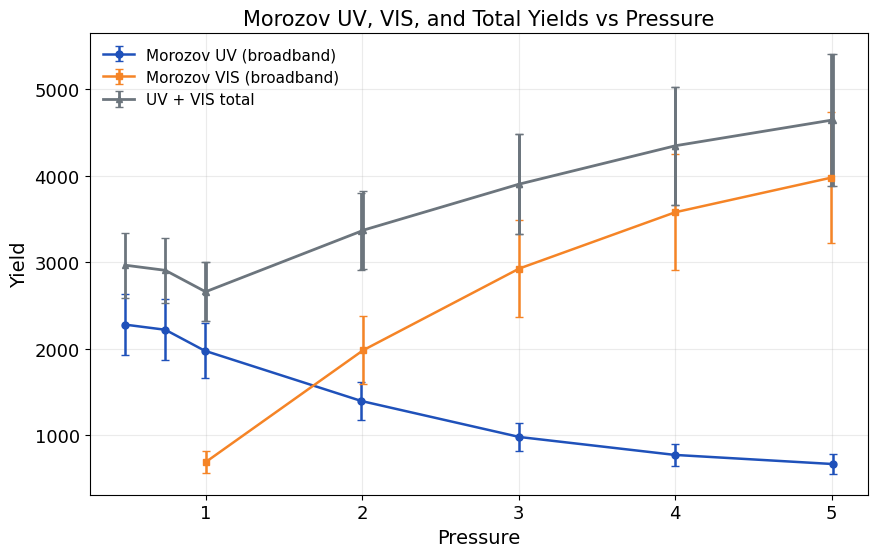

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Knicks palette
knicks_blue = "#1f51ba"
knicks_orange = "#F58426"
knicks_gray = "#6C757D"


def load_morozov_broadband(path):
    # Header row 1: group labels, row 2: X/Y labels
    raw = pd.read_csv(path, header=None)

    # broadband values (x,y) are columns 0,1
    x = pd.to_numeric(raw.iloc[2:, 0], errors="coerce")
    y = pd.to_numeric(raw.iloc[2:, 1], errors="coerce")

    # broadband upErrors are columns 2,3 where col 3 is upper y-trace
    y_up = pd.to_numeric(raw.iloc[2:, 3], errors="coerce")

    out = pd.DataFrame({"x": x, "y": y, "y_up": y_up}).dropna(subset=["x", "y"])
    out["yerr"] = (out["y_up"] - out["y"]).clip(lower=0)
    return out[["x", "y", "yerr"]].sort_values("x").reset_index(drop=True)


uv = load_morozov_broadband("oldStitching/literature_data/morozov_UV_yields.csv")
vis = load_morozov_broadband("oldStitching/literature_data/morozov_VIS_yields.csv")

# Interpolate to common pressure support to build UV+VIS total
p_common = np.union1d(uv["x"].to_numpy(), vis["x"].to_numpy())
uv_y_i = np.interp(p_common, uv["x"], uv["y"])
vis_y_i = np.interp(p_common, vis["x"], vis["y"])
uv_err_i = np.interp(p_common, uv["x"], uv["yerr"])
vis_err_i = np.interp(p_common, vis["x"], vis["yerr"])

total_y = uv_y_i + vis_y_i
total_yerr = np.sqrt(uv_err_i**2 + vis_err_i**2)

fig, ax = plt.subplots(figsize=(9, 5.8))

ax.errorbar(
    uv["x"], uv["y"], yerr=uv["yerr"],
    fmt="o-", markersize=5, capsize=3, linewidth=1.8,
    color=knicks_blue, ecolor=knicks_blue, label="Morozov UV (broadband)"
)

ax.errorbar(
    vis["x"], vis["y"], yerr=vis["yerr"],
    fmt="s-", markersize=5, capsize=3, linewidth=1.8,
    color=knicks_orange, ecolor=knicks_orange, label="Morozov VIS (broadband)"
)

ax.errorbar(
    p_common, total_y, yerr=total_yerr,
    fmt="^-", markersize=5, capsize=3, linewidth=2.0,
    color=knicks_gray, ecolor=knicks_gray, label="UV + VIS total"
)

ax.set_xlabel("Pressure")
ax.set_ylabel("Yield")
ax.set_title("Morozov UV, VIS, and Total Yields vs Pressure")
ax.grid(alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

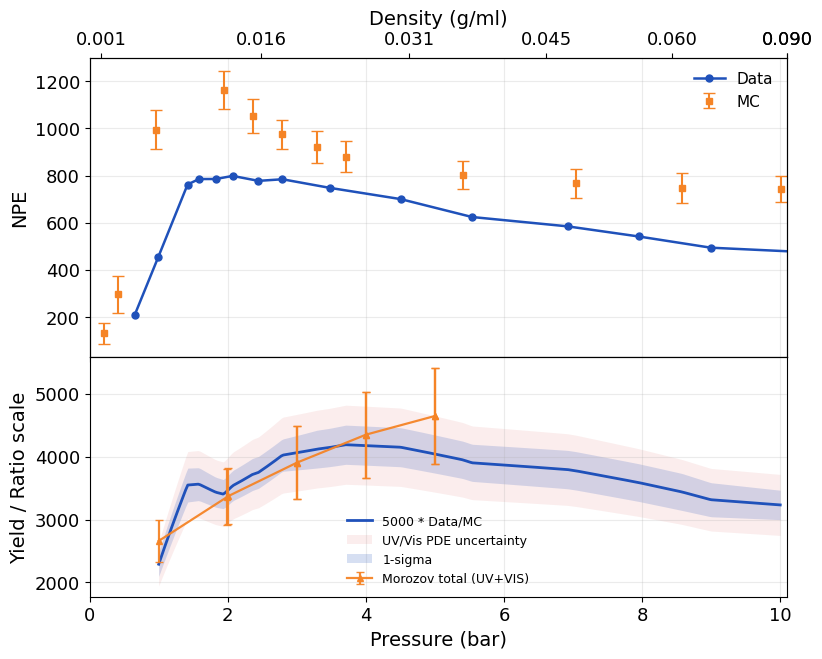

In [43]:
# Plot cell: residual-style figure using results from the math cell above
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

fig, (ax_top_main, ax_resid) = plt.subplots(
    2,
    1,
    figsize=(9, 7.0),
    sharex=True,
    gridspec_kw={"height_ratios": [3.0, 2.4], "hspace": 0.0},
    constrained_layout=False,
)

# Top panel (full pressure range)
ax_top_main.plot(
    data_p_math,
    data_math["y"],
    marker="o",
    markersize=5,
    linestyle="-",
    linewidth=1.8,
    color=knicks_blue,
    label="Data",
)

ax_top_main.errorbar(
    mc_p_math,
    mc_math["y"],
    yerr=mc_yerr_math,
    fmt="s",
    markersize=5,
    capsize=4,
    elinewidth=1.5,
    linewidth=1.5,
    color=knicks_orange,
    ecolor=knicks_orange,
    label="MC",
)

ax_top_main.set_ylabel("NPE")
# ax_top_main.set_title("NPE vs Pressure with Density Top Axis + Ratio Residual")
ax_top_main.grid(alpha=0.25)
ax_top_main.legend(frameon=False)

# Density on top x-axis
ax_density = ax_top_main.twiny()
ax_density.set_xlim(0, 12)
ax_density.set_xticks(p_tick_positions_math)
ax_density.set_xticklabels([f"{r:.3f}" for r in rho_ticks_math])
ax_density.set_xlabel("Density (g/ml)")

# Bottom residual panel: 5000 * Data/MC with propagated 1-sigma band
ax_resid.plot(
    p_ratio_grid_math,
    ratio_scaled_5000_math,
    color=knicks_blue,
    linewidth=2.0,
    label="5000 * Data/MC",
)

# PDE component uncertainty band (±15%), drawn underneath other bands
pde_unc_frac = 0.15
ratio_scaled_5000_pde_lower = ratio_scaled_5000_math * (1.0 - pde_unc_frac)
ratio_scaled_5000_pde_upper = ratio_scaled_5000_math * (1.0 + pde_unc_frac)
ax_resid.fill_between(
    p_ratio_grid_math,
    ratio_scaled_5000_pde_lower,
    ratio_scaled_5000_pde_upper,
    color="#D9534F",
    alpha=0.10,
    linewidth=0,
    zorder=0,
    label="UV/Vis PDE uncertainty",
)

# Lower 1-sigma shaded region
ax_resid.fill_between(
    p_ratio_grid_math,
    ratio_scaled_5000_lower_math,
    ratio_scaled_5000_math,
    color=knicks_blue,
    alpha=0.18,
    linewidth=0,
)

# Upper 1-sigma shaded region
ax_resid.fill_between(
    p_ratio_grid_math,
    ratio_scaled_5000_math,
    ratio_scaled_5000_upper_math,
    color=knicks_blue,
    alpha=0.18,
    linewidth=0,
    label="1-sigma",
)

# ax_resid.axhline(5000.0, color=knicks_orange, linestyle="--", linewidth=1.3, alpha=0.9)

# Overlay Morozov total yield on the same lower axis.
# If Morozov variables are not already in memory, load them here as fallback.
if not all(name in globals() for name in ["p_common", "total_y", "total_yerr"]):
    def _load_morozov_broadband(path):
        raw = pd.read_csv(path, header=None)
        x = pd.to_numeric(raw.iloc[2:, 0], errors="coerce")
        y = pd.to_numeric(raw.iloc[2:, 1], errors="coerce")
        y_up = pd.to_numeric(raw.iloc[2:, 3], errors="coerce")
        out = pd.DataFrame({"x": x, "y": y, "y_up": y_up}).dropna(subset=["x", "y"])
        out["yerr"] = (out["y_up"] - out["y"]).clip(lower=0)
        return out[["x", "y", "yerr"]].sort_values("x").reset_index(drop=True)

    uv_tmp = _load_morozov_broadband("oldStitching/literature_data/morozov_UV_yields.csv")
    vis_tmp = _load_morozov_broadband("oldStitching/literature_data/morozov_VIS_yields.csv")

    p_common = np.union1d(uv_tmp["x"].to_numpy(), vis_tmp["x"].to_numpy())
    uv_y_i = np.interp(p_common, uv_tmp["x"], uv_tmp["y"])
    vis_y_i = np.interp(p_common, vis_tmp["x"], vis_tmp["y"])
    uv_err_i = np.interp(p_common, uv_tmp["x"], uv_tmp["yerr"])
    vis_err_i = np.interp(p_common, vis_tmp["x"], vis_tmp["yerr"])

    total_y = uv_y_i + vis_y_i
    total_yerr = np.sqrt(uv_err_i**2 + vis_err_i**2)

# Do not draw Morozov points below 1 bar
mor_mask = p_common >= 1.0

knicks_gray = "#6C757D"
ax_resid.errorbar(
    p_common[mor_mask],
    total_y[mor_mask],
    yerr=total_yerr[mor_mask],
    fmt="^-",
    markersize=4,
    capsize=3,
    linewidth=1.6,
    color=knicks_orange,
    ecolor=knicks_orange,
    alpha=0.95,
    label="Morozov total (UV+VIS)",
)

ax_resid.set_xlabel("Pressure (bar)")
ax_resid.set_ylabel("Yield / Ratio scale")
ax_resid.grid(alpha=0.25)
ax_resid.legend(frameon=False, fontsize=9)

# Use the same x-axis range on both panels
ax_top_main.set_xlim(0, 10.1)

plt.show()

---
alpha vs r^2


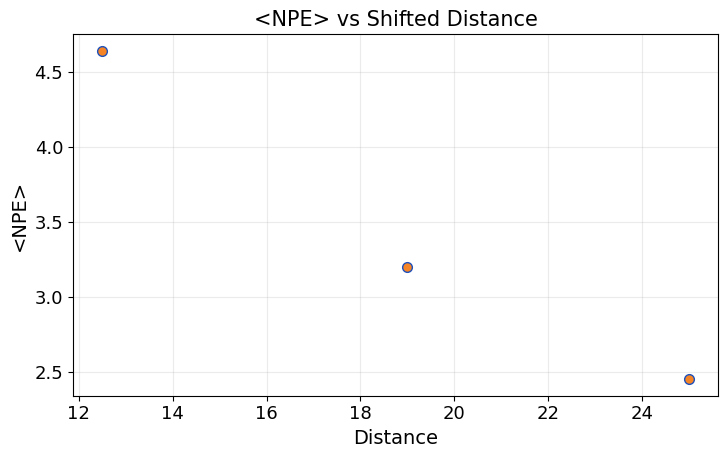

In [44]:
import numpy as np
import matplotlib.pyplot as plt

# Pasted column data: (distance, <NPE>)
distance_raw = np.array([45.0, 39.0, 32.5], dtype=float)
npe = np.array([2.45, 3.20, 4.64], dtype=float)

# Requested conversion
distance = distance_raw - 20.0

# Sort by x for cleaner line plotting
order = np.argsort(distance)
distance = distance[order]
npe = npe[order]

# Knicks colors
knicks_blue = "#1f51ba"
knicks_orange = "#F58426"

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(distance, npe, marker = 'o', color=knicks_blue, linestyle = "None",
        markerfacecolor=knicks_orange, markeredgecolor=knicks_blue,
        linewidth=2.0, markersize=7,
)

ax.set_xlabel("Distance")
ax.set_ylabel("<NPE>")
ax.set_title("<NPE> vs Shifted Distance")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [50]:
import numpy as np
import matplotlib.pyplot as plt
from iminuit import Minuit
from iminuit.cost import LeastSquares

# Use shifted-distance arrays from the previous cell
r_fit = np.asarray(distance, dtype=float)
y_fit = np.asarray(npe, dtype=float)

# Unweighted least-squares (all points given equal weight)
y_err = np.ones_like(y_fit)


def model(r, A, d):
    return A / (r + d) ** 2


# Fit 1: d fixed to 0
def model_d0(r, A):
    return model(r, A, 0.0)


lsq_d0 = LeastSquares(r_fit, y_fit, y_err, model_d0)
m_d0 = Minuit(lsq_d0, A=np.max(y_fit) * np.mean(r_fit) ** 2)
m_d0.limits["A"] = (0.0, None)
m_d0.migrad()
m_d0.hesse()

# Fit 2: d floating
lsq_free = LeastSquares(r_fit, y_fit, y_err, model)
m_free = Minuit(lsq_free, A=m_d0.values["A"], d=10.0)
m_free.limits["A"] = (0.0, None)
m_free.limits["d"] = (-10.0, 80.0)
m_free.migrad()
m_free.hesse()

# Print fit summaries
print("Fit 1 (d fixed = 0):")
print(f"  A = {m_d0.values['A']:.3f} +/- {m_d0.errors['A']:.3f}")
print(f"  chi2/ndof = {m_d0.fval:.3f}/{len(r_fit)-1}")

print("\nFit 2 (d floating):")
print(f"  A = {m_free.values['A']:.3f} +/- {m_free.errors['A']:.3f}")
print(f"  d = {m_free.values['d']:.3f} +/- {m_free.errors['d']:.3f} mm")
print(f"  chi2/ndof = {m_free.fval:.3f}/{len(r_fit)-2}")

# Knicks-style plot
knicks_blue = "#1f51ba"
knicks_orange = "#F58426"
knicks_gray = "#6C757D"

r_grid = np.linspace(max(0.0, r_fit.min() - 2), r_fit.max() + 2, 300)

Fit 1 (d fixed = 0):
  A = 829.801 +/- 139.763
  chi2/ndof = 2.522/2

Fit 2 (d floating):
  A = 4971.407 +/- 4972.407
  d = 20.267 +/- 23.138 mm
  chi2/ndof = 0.001/1


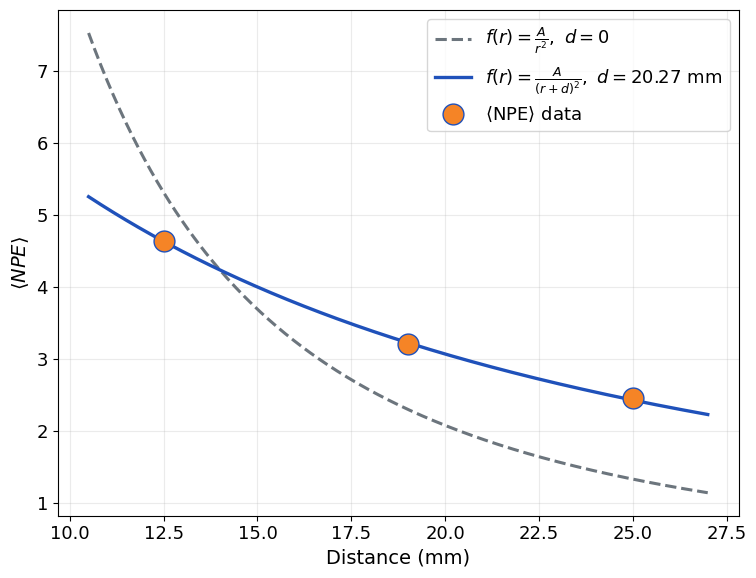

In [53]:
fig, ax = plt.subplots(figsize=(7.8, 6))

# Draw fit curves first
ax.plot(
    r_grid,
    model_d0(r_grid, m_d0.values["A"]),
    color=knicks_gray,
    linewidth=2.2,
    linestyle="--",
    zorder=2,
    label=rf"$f(r)=\frac{{A}}{{r^2}},\ d=0$",
)

ax.plot(
    r_grid,
    model(r_grid, m_free.values["A"], m_free.values["d"]),
    color=knicks_blue,
    linewidth=2.4,
    zorder=3,
    label=rf"$f(r)=\frac{{A}}{{(r+d)^2}},\ d={m_free.values['d']:.2f}\ \mathrm{{mm}}$",
)

# Draw data points on top
ax.plot(
    r_fit,
    y_fit,
    marker="o",
    linestyle="None",
    color=knicks_blue,
    markerfacecolor=knicks_orange,
    markeredgecolor=knicks_blue,
    markersize=15,
    zorder=10,
    label=r"$\langle\mathrm{NPE}\rangle\ \mathrm{data}$",
)

ax.set_xlabel("Distance (mm)")
ax.set_ylabel(r"$\langle NPE \rangle$")
ax.grid(alpha=0.25)
ax.legend(frameon=True, fontsize = 13)

plt.tight_layout()
plt.show()
